# HW1 — Introduction and Learnability
## From PAC to Agnostic PAC learning with threshold classifiers

**Student:** Filip BARBUTOV  
**Program:** M2 IM  
**Course:** Statistical and Machine Learning, Université de Haute-Alsace

**Goal.** Illustrate experimentally the difference between the **PAC** (realizable) and the **Agnostic PAC** learning frameworks, using an Empirical Risk Minimization (ERM) learner over the class of threshold classifiers on $\mathcal{X}=[0,1]$.

**Outline**
0. Setup and experimental design (choice of $\theta$, $\varepsilon$, $\delta$, $\eta$, sample sizes, repetitions)
1. Data generation
2. Implementation of ERM
3. Performance evaluation (empirical vs. true error)
4. Experimental verification of PAC learning
5. From PAC to Agnostic PAC (label noise)
6. Conclusion

Only `numpy` (computations) and `matplotlib` (plots) are used. The learning algorithm is implemented from scratch.

## 0. Setup and experimental design

### Learning problem
- Input space $\mathcal{X}=[0,1]$, inputs $x\sim\mathcal{U}[0,1]$.
- Target: $f_\theta(x)=\mathbb{1}[x>\theta]$.
- Hypothesis class: $\mathcal{H}=\{h_t(x)=\mathbb{1}[x>t] : t\in[0,1]\}$, so the target belongs to $\mathcal{H}$.
- **Realizable setting:** $y=f_\theta(x)$.
- **Agnostic setting:** $y=f_\theta(x)$ flipped independently with probability $\eta$.

### Parameter choices (and why)
| Parameter | Value | Justification |
|---|---|---|
| $\theta$ | $0.35$ | Not at the centre of $[0,1]$, to avoid symmetric special cases. $[\theta-\varepsilon,\theta+\varepsilon]\subset[0,1]$. |
| $\varepsilon$ | $0.05$ | A demanding but reachable accuracy for $m\le 200$. Other values are also studied in §4. |
| $\delta$ | $0.05$ | Standard 95 % confidence level. |
| $\eta$ | $0.1$ (main), sweep over $\{0.05,0.1,0.2,0.3,0.4\}$ | $\eta=0.1$ is larger than $\varepsilon$, which makes the PAC/Agnostic contrast visible. The sweep studies how noise affects learning. |
| $m$ | $\{5,10,20,50,100,200\}$ (+ $\{500,1000,2000,5000\}$ in §5) | The sizes required by the assignment, extended to observe asymptotic behaviour in the noisy case. |
| Repetitions $R$ | $1000$ | The standard error of an estimated probability is at most $\sqrt{0.25/1000}\approx 0.016$. |
| Test set size | $100\,000$ | The standard error of the estimated true error is $\le\sqrt{0.25/10^5}\approx 0.0016$. |

A fixed random seed makes every result in this notebook reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- Global experimental parameters ----------------
SEED       = 42
THETA      = 0.35                     # target threshold
EPS        = 0.05                     # accuracy parameter epsilon
DELTA      = 0.05                     # confidence parameter delta
ETA        = 0.10                     # label-noise rate (agnostic setting)
ETAS       = [0.05, 0.10, 0.20, 0.30, 0.40]
M_LIST     = [5, 10, 20, 50, 100, 200]
M_LIST_EXT = M_LIST + [500, 1000, 2000, 5000]
R          = 1000                     # number of repetitions
N_TEST     = 100_000                  # size of the independent test set

rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
C_REAL, C_NOISY = "tab:blue", "tab:red"

## 1. Data generation

`generate_data(m, theta, eta, rng)` draws $m$ points uniformly in $[0,1]$, labels them with $f_\theta$ and, if $\eta>0$, flips each label independently with probability $\eta$. With $\eta=0$ it produces the realizable setting, with $\eta>0$ the agnostic one.

In [2]:
def generate_data(m, theta=THETA, eta=0.0, rng=rng):
    # Draw m i.i.d. examples: x ~ U[0,1], y = 1[x > theta], each label flipped w.p. eta.
    x = rng.uniform(0.0, 1.0, size=m)
    y = (x > theta).astype(int)
    if eta > 0:
        flip = rng.uniform(0.0, 1.0, size=m) < eta
        y = np.where(flip, 1 - y, y)
    return x, y

# One training set per sample size, in both settings
datasets_real  = {m: generate_data(m, eta=0.0) for m in M_LIST}
datasets_noisy = {m: generate_data(m, eta=ETA) for m in M_LIST}

for m in M_LIST:
    x, y = datasets_noisy[m]
    n_flipped = int(np.sum(y != (x > THETA)))
    print(f"m = {m:4d} | realizable: {datasets_real[m][1].sum():3d} positives "
          f"| noisy: {n_flipped:3d} flipped labels ({n_flipped/m:.0%})")

m =    5 | realizable:   4 positives | noisy:   1 flipped labels (20%)
m =   10 | realizable:   9 positives | noisy:   2 flipped labels (20%)
m =   20 | realizable:  14 positives | noisy:   3 flipped labels (15%)
m =   50 | realizable:  31 positives | noisy:   6 flipped labels (12%)
m =  100 | realizable:  64 positives | noisy:  10 flipped labels (10%)
m =  200 | realizable: 128 positives | noisy:  13 flipped labels (6%)


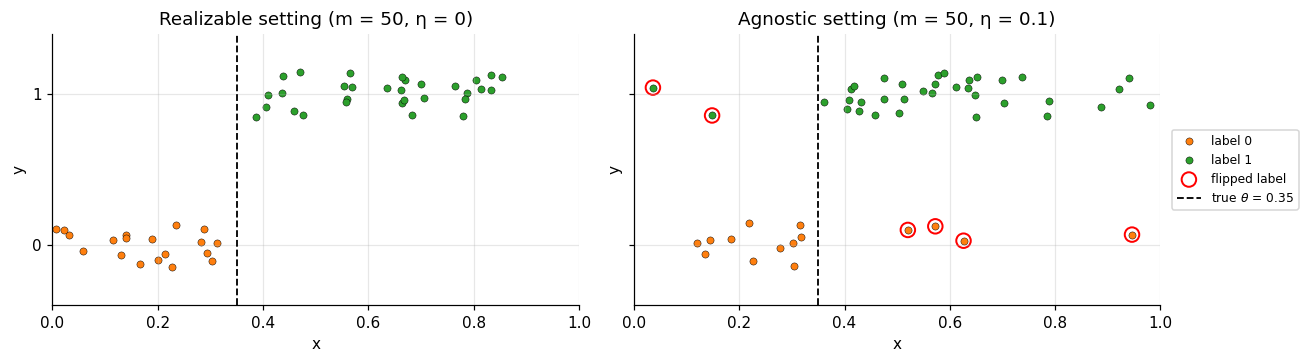

In [3]:
def plot_dataset(ax, x, y, theta=THETA, title="", t_hat=None):
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, size=len(x))
    ax.scatter(x[y == 0], y[y == 0] + jitter[y == 0], c="tab:orange", s=22, label="label 0", edgecolor="k", lw=0.3)
    ax.scatter(x[y == 1], y[y == 1] + jitter[y == 1], c="tab:green",  s=22, label="label 1", edgecolor="k", lw=0.3)
    wrong = y != (x > theta)
    if wrong.any():
        ax.scatter(x[wrong], y[wrong] + jitter[wrong], facecolors="none", edgecolors="red", s=90, lw=1.3, label="flipped label")
    ax.axvline(theta, color="k", ls="--", lw=1.2, label=fr"true $\theta$ = {theta}")
    if t_hat is not None:
        ax.axvline(t_hat, color="tab:purple", lw=1.8, label=fr"ERM $\hat t$ = {t_hat:.3f}")
    ax.set_xlim(0, 1); ax.set_yticks([0, 1]); ax.set_ylim(-0.4, 1.4)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
plot_dataset(axes[0], *datasets_real[50],  title="Realizable setting (m = 50, η = 0)")
plot_dataset(axes[1], *datasets_noisy[50], title=f"Agnostic setting (m = 50, η = {ETA})")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.show()

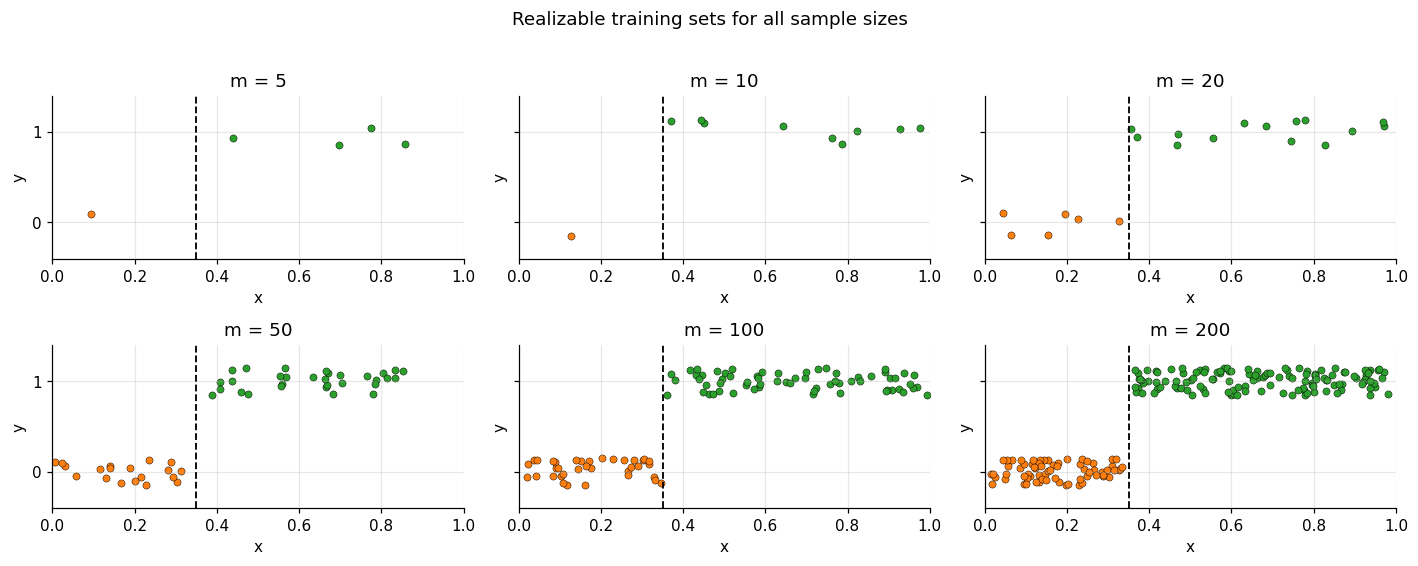

In [4]:
# Overview of all training sizes (realizable setting)
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharey=True)
for ax, m in zip(axes.ravel(), M_LIST):
    plot_dataset(ax, *datasets_real[m], title=f"m = {m}")
plt.suptitle("Realizable training sets for all sample sizes", y=1.02)
plt.tight_layout(); plt.show()


**Observations.**
- In the realizable setting the two classes are **perfectly separated** at $\theta=0.35$: every point left of $\theta$ has label 0 and every point to the right has label 1. A threshold with zero training error always exists.
- In the agnostic setting some labels are flipped (red circles) on **both** sides of $\theta$. No threshold can classify all points correctly anymore.
- The observed proportion of flipped labels fluctuates around $\eta=0.1$ for small samples (20 % at $m=5$ and $m=10$, 6 % at $m=200$). This is ordinary sampling noise, and already a reminder that small samples can be misleading.
- For small $m$ there are few points near $\theta$, so a whole interval of thresholds separates the data equally well. The learner cannot know where exactly $\theta$ lies in that interval. This uncertainty is the source of the true error in the realizable case.


## 2. Implementation of ERM

### Strategy
ERM returns $\hat t\in\arg\min_{t\in[0,1]} L_S(h_t)$ with $L_S(h_t)=\frac1m\sum_i \mathbb{1}[h_t(x_i)\ne y_i]$.

Although $\mathcal{H}$ is **infinite**, the empirical error $L_S(h_t)$ only changes when $t$ crosses a training point. So only $m+1$ different behaviours exist on the sample. If $x_{(1)}\le\dots\le x_{(m)}$ are the sorted inputs, a threshold placed between $x_{(k)}$ and $x_{(k+1)}$ predicts $0$ for the first $k$ points and $1$ for the others. Its number of mistakes is

$$
\text{err}(k)=\underbrace{\#\{i\le k : y_{(i)}=1\}}_{\text{positives predicted }0}+\underbrace{\#\{i>k : y_{(i)}=0\}}_{\text{negatives predicted }1},\qquad k=0,\dots,m .
$$

With cumulative sums, all $m+1$ values are computed at once, so the algorithm runs in $O(m\log m)$ time (dominated by sorting). It finds the **exact** empirical risk minimizer over the whole infinite class.

**Choice of the threshold inside the optimal gap.** Every $t\in(x_{(k)},x_{(k+1)})$ has the same empirical error, so we return the **midpoint** $\hat t=(x_{(k)}+x_{(k+1)})/2$. This is a max-margin choice: it does not systematically bias $\hat t$ towards one class. Edge cases: $k=0$ gives $\hat t=0$ (everything predicted 1) and $k=m$ gives $\hat t=1$ (everything predicted 0). If several gaps reach the minimum (possible with noise), we take the **median** of the optimal gaps, again to avoid a systematic bias.

In [5]:
def erm_threshold(x, y):
    # Exact ERM over H = {1[x > t] : t in [0,1]}. Returns (t_hat, empirical_error).
    m = len(x)
    order = np.argsort(x)
    xs, ys = x[order], y[order]
    k = np.arange(m + 1)                                   # number of points predicted 0
    pos_left  = np.concatenate([[0], np.cumsum(ys)])       # positives among the first k points
    neg_right = (m - k) - (ys.sum() - pos_left)            # negatives among the last m-k points
    errors = pos_left + neg_right
    best = np.flatnonzero(errors == errors.min())
    kb = best[len(best) // 2]                              # median optimal gap (tie-breaking)
    if kb == 0:
        t_hat = 0.0
    elif kb == m:
        t_hat = 1.0
    else:
        t_hat = 0.5 * (xs[kb - 1] + xs[kb])                # midpoint of the optimal gap
    return t_hat, errors[kb] / m

def empirical_error(t, x, y):
    return np.mean((x > t).astype(int) != y)

### Sanity checks
1. In the realizable setting ERM must always reach $L_S=0$.
2. The fast algorithm must agree with a naive brute-force search over a fine grid of thresholds.

In [6]:
check_rng = np.random.default_rng(123)
ok_zero, ok_brute = 0, 0
grid = np.linspace(0, 1, 20001)
for _ in range(300):
    m = check_rng.integers(5, 200)
    # 1) realizable: empirical error must be 0
    x, y = generate_data(m, eta=0.0, rng=check_rng)
    t, ls = erm_threshold(x, y)
    ok_zero += (ls == 0) and (empirical_error(t, x, y) == 0)
    # 2) noisy: compare with brute force over a fine grid
    x, y = generate_data(m, eta=0.2, rng=check_rng)
    t, ls = erm_threshold(x, y)
    brute = min(empirical_error(g, x, y) for g in grid[::20])
    ok_brute += np.isclose(ls, empirical_error(t, x, y)) and ls <= brute + 1e-12
print(f"Realizable runs with L_S = 0         : {ok_zero}/300")
print(f"Noisy runs where ERM <= brute force : {ok_brute}/300")

Realizable runs with L_S = 0         : 300/300
Noisy runs where ERM <= brute force : 300/300


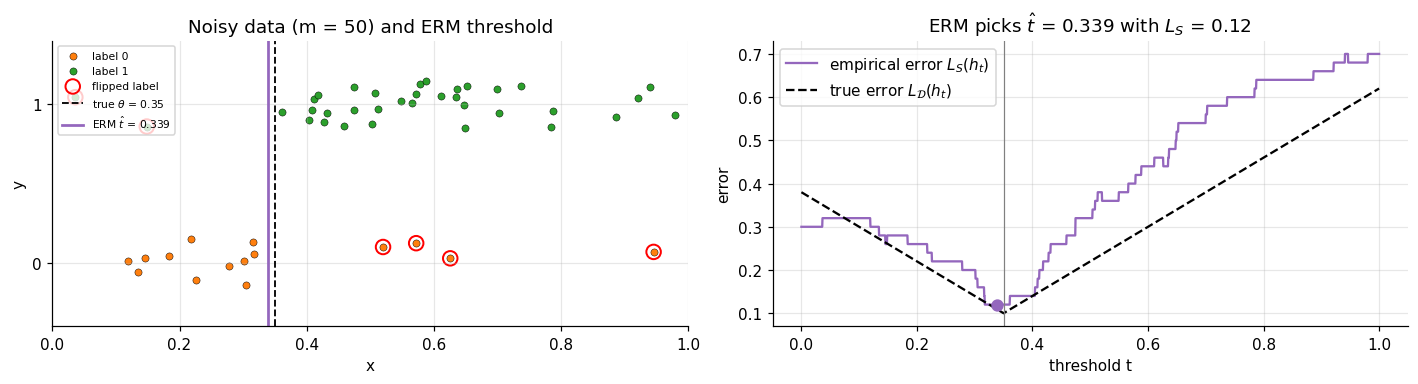

In [7]:
# Visualising ERM: empirical error as a function of t, for one noisy dataset
x, y = datasets_noisy[50]
t_hat, ls_hat = erm_threshold(x, y)
ts = np.linspace(0, 1, 2001)
ls_curve = [empirical_error(t, x, y) for t in ts]
ld_curve = ETA + (1 - 2 * ETA) * np.abs(ts - THETA)       # true error (derived in Section 3)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
plot_dataset(axes[0], x, y, title=f"Noisy data (m = 50) and ERM threshold", t_hat=t_hat)
axes[0].legend(fontsize=7, loc="upper left")
axes[1].plot(ts, ls_curve, color="tab:purple", label=r"empirical error $L_S(h_t)$")
axes[1].plot(ts, ld_curve, color="k", ls="--", label=r"true error $L_\mathcal{D}(h_t)$")
axes[1].scatter([t_hat], [ls_hat], color="tab:purple", zorder=5, s=50)
axes[1].axvline(THETA, color="gray", lw=0.8)
axes[1].set_xlabel("threshold t"); axes[1].set_ylabel("error"); axes[1].legend()
axes[1].set_title(fr"ERM picks $\hat t$ = {t_hat:.3f} with $L_S$ = {ls_hat:.2f}")
plt.tight_layout(); plt.show()


**Observations.**
- Both sanity checks pass (300/300): ERM always reaches zero empirical error on realizable data, and it is never worse than a brute-force search on noisy data. The implementation is therefore an **exact** ERM over the (infinite) class of thresholds.
- The empirical error $L_S(h_t)$ (purple) is a **step function** of $t$: it only changes when $t$ crosses a training point, which is why testing $m+1$ gaps is enough.
- The true error $L_{\mathcal D}(h_t)=\eta+(1-2\eta)|t-\theta|$ (dashed) is V-shaped with minimum $\eta=0.1$ at $t=\theta$.
- ERM selects $\hat t=0.339$, very close to $\theta=0.35$. Its empirical error is $0.12$: the 6 flipped points out of 50 cannot be fitted by any threshold. The empirical curve is a noisy version of the true curve, and the two minima almost coincide. This is the intuition behind ERM: **minimising what we observe approximately minimises what we care about.**


## 3. Performance evaluation

### True error: Monte-Carlo estimate and closed form
The assignment asks to estimate the true error with a large independent test set. For this problem we can also compute it **exactly**, which lets us validate the test-set estimate and later run thousands of repetitions cheaply.

- **Realizable:** $h_{\hat t}$ and $f_\theta$ disagree exactly on the interval between $\hat t$ and $\theta$. Since $x\sim\mathcal U[0,1]$,
$$L_{\mathcal D}(h_{\hat t})=|\hat t-\theta|.$$
- **Agnostic:** on the disagreement interval the prediction is wrong unless the label was flipped (probability $1-\eta$ of an error). Elsewhere it is wrong only if the label was flipped (probability $\eta$). Hence
$$L_{\mathcal D}(h_{\hat t})=\eta\,(1-|\hat t-\theta|)+(1-\eta)\,|\hat t-\theta|=\eta+(1-2\eta)\,|\hat t-\theta| .$$
In particular, the best achievable error in $\mathcal H$ is $\min_{h\in\mathcal H}L_{\mathcal D}(h)=\eta$, reached at $t=\theta$ (for $\eta<1/2$). This is also the Bayes error.

In [8]:
def true_error_exact(t, theta=THETA, eta=0.0):
    return eta + (1 - 2 * eta) * np.abs(t - theta)

# Independent test sets (never used for training)
x_test_real,  y_test_real  = generate_data(N_TEST, eta=0.0)
x_test_noisy, y_test_noisy = generate_data(N_TEST, eta=ETA)

def true_error_test(t, x_test, y_test):
    return empirical_error(t, x_test, y_test)

rows = []
for setting, data, (xt, yt), eta in [("realizable", datasets_real, (x_test_real, y_test_real), 0.0),
                                     ("agnostic",   datasets_noisy, (x_test_noisy, y_test_noisy), ETA)]:
    for m in M_LIST:
        t_hat, ls = erm_threshold(*data[m])
        rows.append((setting, m, t_hat, ls, true_error_test(t_hat, xt, yt), true_error_exact(t_hat, eta=eta)))

print(f"{'setting':<11}{'m':>5}{'t_hat':>9}{'L_S':>9}{'L_D (test)':>12}{'L_D (exact)':>13}{'gap L_D-L_S':>13}")
for s, m, t, ls, ldt, lde in rows:
    print(f"{s:<11}{m:>5}{t:>9.4f}{ls:>9.4f}{ldt:>12.4f}{lde:>13.4f}{ldt - ls:>13.4f}")

setting        m    t_hat      L_S  L_D (test)  L_D (exact)  gap L_D-L_S
realizable     5   0.2665   0.0000      0.0820       0.0835       0.0820
realizable    10   0.2495   0.0000      0.0997       0.1005       0.0997
realizable    20   0.3402   0.0000      0.0096       0.0098       0.0096
realizable    50   0.3499   0.0000      0.0001       0.0001       0.0001
realizable   100   0.3543   0.0000      0.0046       0.0043       0.0046
realizable   200   0.3489   0.0000      0.0012       0.0011       0.0012
agnostic       5   0.9009   0.2000      0.5383       0.5407       0.3383
agnostic      10   0.3721   0.2000      0.1168       0.1177      -0.0832
agnostic      20   0.4234   0.1500      0.1591       0.1587       0.0091
agnostic      50   0.3388   0.1200      0.1090       0.1089      -0.0110
agnostic     100   0.3566   0.1000      0.1050       0.1052       0.0049
agnostic     200   0.3540   0.0650      0.1028       0.1032       0.0378


A single training set per size is noisy. To compare empirical and true errors reliably, we repeat the experiment $R=1000$ times per sample size. We use the exact formula for $L_{\mathcal D}$: the table above shows it agrees with the test-set estimate up to Monte-Carlo error ($\approx 10^{-3}$).

In [9]:
def run_experiment(m_list, eta, R=R, theta=THETA, rng=rng):
    # Repeat (sample -> ERM -> evaluate) R times. Returns dict m -> (t_hats, L_S, L_D).
    out = {}
    for m in m_list:
        t_hats, LS, LD = np.empty(R), np.empty(R), np.empty(R)
        for r in range(R):
            x, y = generate_data(m, theta=theta, eta=eta, rng=rng)
            t_hats[r], LS[r] = erm_threshold(x, y)
        LD = true_error_exact(t_hats, theta=theta, eta=eta)
        out[m] = (t_hats, LS, LD)
    return out

res_real  = run_experiment(M_LIST_EXT, eta=0.0)
res_noisy = run_experiment(M_LIST_EXT, eta=ETA)

def summary(res, m_list):
    return (np.array([res[m][1].mean() for m in m_list]), np.array([res[m][2].mean() for m in m_list]),
            np.array([res[m][1].std()  for m in m_list]), np.array([res[m][2].std()  for m in m_list]))

LSr, LDr, sLSr, sLDr = summary(res_real, M_LIST)
print(f"{'m':>5} | {'mean L_S':>9} {'mean L_D':>9} {'std L_D':>8}   (realizable, R = {R})")
for i, m in enumerate(M_LIST):
    print(f"{m:>5} | {LSr[i]:>9.4f} {LDr[i]:>9.4f} {sLDr[i]:>8.4f}")

    m |  mean L_S  mean L_D  std L_D   (realizable, R = 1000)
    5 |    0.0000    0.1040   0.1167
   10 |    0.0000    0.0502   0.0601
   20 |    0.0000    0.0249   0.0234
   50 |    0.0000    0.0098   0.0097
  100 |    0.0000    0.0048   0.0047
  200 |    0.0000    0.0025   0.0025


**Cross-check with the independent test set for every repetition.** The assignment asks for the true error to be computed with a large independent test set. Below we evaluate **every one of the $R=1000$ learned hypotheses, for every $m$ and both settings**, on the test sets of size $100\,000$, and compare with the closed form. Since the test set is fixed, each evaluation costs only one binary search on the sorted test inputs.

In [10]:
def true_error_test_fast(t_hats, x_test, y_test):
    # Test-set error of many thresholds at once (sorted test set + cumulative sums)
    order = np.argsort(x_test); xs, ys = x_test[order], y_test[order]; n = len(xs)
    pos_left_all = np.concatenate([[0], np.cumsum(ys)])
    k = np.searchsorted(xs, t_hats, side="right")            # test points predicted 0
    pos_left = pos_left_all[k]
    neg_right = (n - k) - (ys.sum() - pos_left)
    return (pos_left + neg_right) / n

print(f"{'setting':<11}{'m':>5} | {'max |test - exact|':>19} | {'P(L>crit) test':>15} | {'P(L>crit) exact':>16}")
for name, res, (xt, yt), eta in [("realizable", res_real,  (x_test_real,  y_test_real),  0.0),
                                 ("agnostic",   res_noisy, (x_test_noisy, y_test_noisy), ETA)]:
    crit = EPS + eta                                           # eps (realizable) or eta + eps (agnostic)
    for m in M_LIST:
        t_hats, _, LD_exact = res[m]
        LD_test = true_error_test_fast(t_hats, xt, yt)
        print(f"{name:<11}{m:>5} | {np.max(np.abs(LD_test - LD_exact)):>19.4f} | "
              f"{np.mean(LD_test > crit):>15.3f} | {np.mean(LD_exact > crit):>16.3f}")

setting        m |  max |test - exact| |  P(L>crit) test |  P(L>crit) exact
realizable     5 |              0.0020 |           0.588 |            0.597
realizable    10 |              0.0019 |           0.342 |            0.349
realizable    20 |              0.0016 |           0.130 |            0.132
realizable    50 |              0.0016 |           0.006 |            0.006
realizable   100 |              0.0008 |           0.000 |            0.000
realizable   200 |              0.0007 |           0.000 |            0.000
agnostic       5 |              0.0026 |           0.643 |            0.646
agnostic      10 |              0.0025 |           0.452 |            0.453
agnostic      20 |              0.0023 |           0.242 |            0.243
agnostic      50 |              0.0016 |           0.074 |            0.074
agnostic     100 |              0.0011 |           0.021 |            0.021
agnostic     200 |              0.0009 |           0.000 |            0.000


The test-set estimate and the closed form differ by at most a few thousandths for all $2\times6\times1000$ hypotheses, and they give the same failure probabilities up to Monte-Carlo noise. In the rest of the notebook we therefore use the exact formula. It is free of test-set noise and makes the larger experiments of §5 (up to $m=5000$, several noise levels) fast.

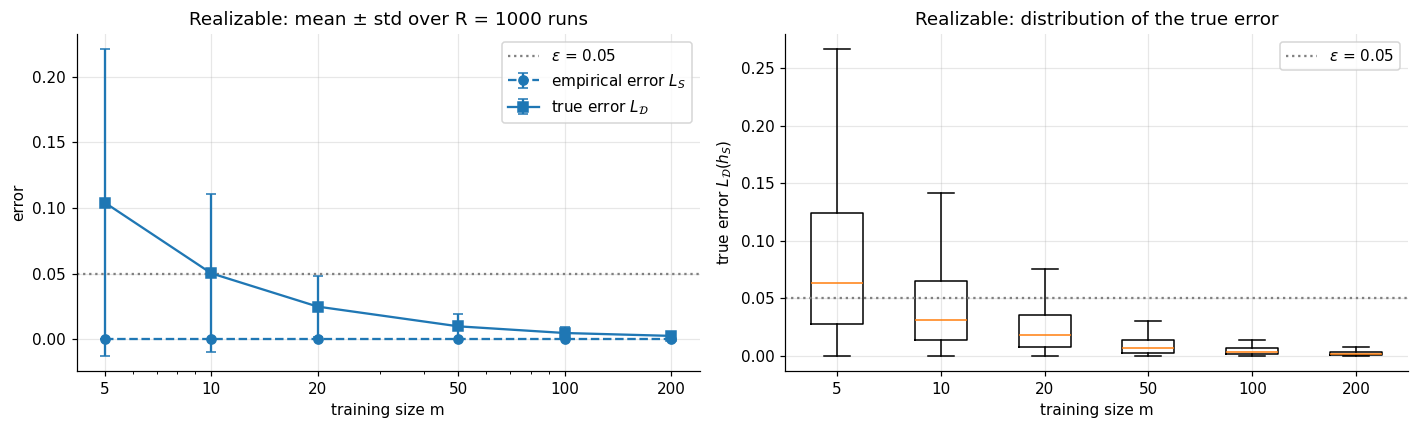

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.errorbar(M_LIST, LSr, yerr=sLSr, marker="o", capsize=3, color=C_REAL, ls="--", label=r"empirical error $L_S$")
ax.errorbar(M_LIST, LDr, yerr=sLDr, marker="s", capsize=3, color=C_REAL, label=r"true error $L_\mathcal{D}$")
ax.axhline(EPS, color="gray", ls=":", label=fr"$\varepsilon$ = {EPS}")
ax.set_xscale("log"); ax.set_xticks(M_LIST); ax.set_xticklabels(M_LIST)
ax.set_xlabel("training size m"); ax.set_ylabel("error"); ax.legend()
ax.set_title("Realizable: mean ± std over R = 1000 runs")

ax = axes[1]
ax.boxplot([res_real[m][2] for m in M_LIST], showfliers=False)
ax.set_xticks(range(1, len(M_LIST) + 1), M_LIST)
ax.axhline(EPS, color="gray", ls=":", label=fr"$\varepsilon$ = {EPS}")
ax.set_xlabel("training size m"); ax.set_ylabel(r"true error $L_\mathcal{D}(h_S)$"); ax.legend()
ax.set_title("Realizable: distribution of the true error")
plt.tight_layout(); plt.show()


**Observations.**
- **Validation of the closed form.** On every training set, the test-set estimate and the exact formula differ by at most $0.003$, which is the expected Monte-Carlo precision. We can therefore use the exact formula in the repeated experiments.
- **Realizable setting.** The empirical error is always $0$, yet the true error is not: $0.08$ at $m=5$, $0.10$ at $m=10$ (an unlucky sample), and about $0.001$ at $m=200$. A zero training error does **not** guarantee a small true error, especially with little data. Here the generalisation gap $L_{\mathcal D}-L_S$ equals the true error itself.
- **Agnostic setting (single runs).** The empirical error is never $0$ for $m\ge10$, and the true error never goes below $\eta=0.1$. With $m=5$ the noisy sample misleads ERM completely ($\hat t=0.90$, $L_{\mathcal D}=0.54$). The gap $L_{\mathcal D}-L_S$ can even be negative on a single run (e.g. $m=10$): by chance the sample contained more flipped labels than average.
- **Averages over 1000 runs (realizable).** The mean true error is $0.104,\,0.050,\,0.025,\,0.0098,\,0.0048,\,0.0025$ for $m=5,\dots,200$: it is roughly **halved each time $m$ doubles**, i.e. $\mathbb E[L_{\mathcal D}(h_S)]\approx 0.5/m$. This matches the geometry of the problem: the gap between the last negative and the first positive point has expected length $\approx 1/m$, and the midpoint rule makes an error of about half of it. The variance also shrinks (std from $0.117$ to $0.0025$): the learner becomes both **more accurate** and **more reliable**.


## 4. Experimental verification of PAC learning

The class of thresholds is PAC learnable in the realizable setting. For each $m$ we estimate
$$\widehat{\Pr}\big(L_{\mathcal D}(h_S)>\varepsilon\big)=\frac1R\sum_{r=1}^R\mathbb 1\big[L_{\mathcal D}(h_{S_r})>\varepsilon\big]$$
and check that it falls below $\delta$ when $m$ is large enough.

### A theoretical bound for comparison
For ERM with the midpoint rule, $L_{\mathcal D}(h_S)=|\hat t-\theta|>\varepsilon$ requires $\hat t>\theta+\varepsilon$ or $\hat t<\theta-\varepsilon$.
- If $\hat t>\theta+\varepsilon$, then the smallest positive example lies beyond $\theta+\varepsilon$, so **no** training point fell in $(\theta,\theta+\varepsilon]$. This happens with probability $(1-\varepsilon)^m$, using independence of the samples.
- Symmetrically on the left side.

By the **union bound** (the same tool as in the lecture's proof):
$$\Pr\big(L_{\mathcal D}(h_S)>\varepsilon\big)\le 2(1-\varepsilon)^m\le 2e^{-\varepsilon m},
\qquad\text{so}\qquad m\ge\frac{\ln(2/\delta)}{\varepsilon}\ \text{suffices.}$$

We also compare with the lecture's **finite-class** bound $m\ge\ln(|\mathcal H|/\delta)/\varepsilon$, applied to a discretised version of $\mathcal H$ with thresholds stored on a grid of $|\mathcal H|=1000$ values (≈ 10 bits). This uses the discretisation argument of the course.

In [12]:
def prob_exceed(res, m_list, eps, offset=0.0):
    # Fraction of runs with L_D(h_S) - offset > eps
    return np.array([np.mean(res[m][2] - offset > eps) for m in m_list])

def wilson_ci(p, n=R, z=1.96):
    # 95% Wilson confidence interval for an estimated probability
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

P_real = prob_exceed(res_real, M_LIST, EPS)
bound_thr = np.minimum(1, 2 * (1 - EPS) ** np.array(M_LIST))

m_needed_thr    = int(np.ceil(np.log(2 / DELTA) / EPS))
m_needed_finite = int(np.ceil(np.log(1000 / DELTA) / EPS))
m_emp = next((m for m in M_LIST_EXT if prob_exceed(res_real, [m], EPS)[0] <= DELTA), None)

print(f"{'m':>5} | {'P_hat(L_D > eps)':>17} | {'95% CI':>17} | {'bound 2(1-eps)^m':>17}")
lo, hi = wilson_ci(P_real)
for i, m in enumerate(M_LIST):
    print(f"{m:>5} | {P_real[i]:>17.3f} | [{lo[i]:.3f}, {hi[i]:.3f}] | {bound_thr[i]:>17.3f}")
print(f"\nSmallest tested m with P_hat <= delta = {DELTA}  : m = {m_emp}")
print(f"Sufficient m, threshold bound ln(2/delta)/eps   : m >= {m_needed_thr}")
print(f"Sufficient m, finite-class bound (|H| = 1000)   : m >= {m_needed_finite}")

    m |  P_hat(L_D > eps) |            95% CI |  bound 2(1-eps)^m
    5 |             0.597 | [0.566, 0.627] |             1.000
   10 |             0.349 | [0.320, 0.379] |             1.000
   20 |             0.132 | [0.112, 0.154] |             0.717
   50 |             0.006 | [0.003, 0.013] |             0.154
  100 |             0.000 | [0.000, 0.004] |             0.012
  200 |             0.000 | [0.000, 0.004] |             0.000

Smallest tested m with P_hat <= delta = 0.05  : m = 50
Sufficient m, threshold bound ln(2/delta)/eps   : m >= 74
Sufficient m, finite-class bound (|H| = 1000)   : m >= 199


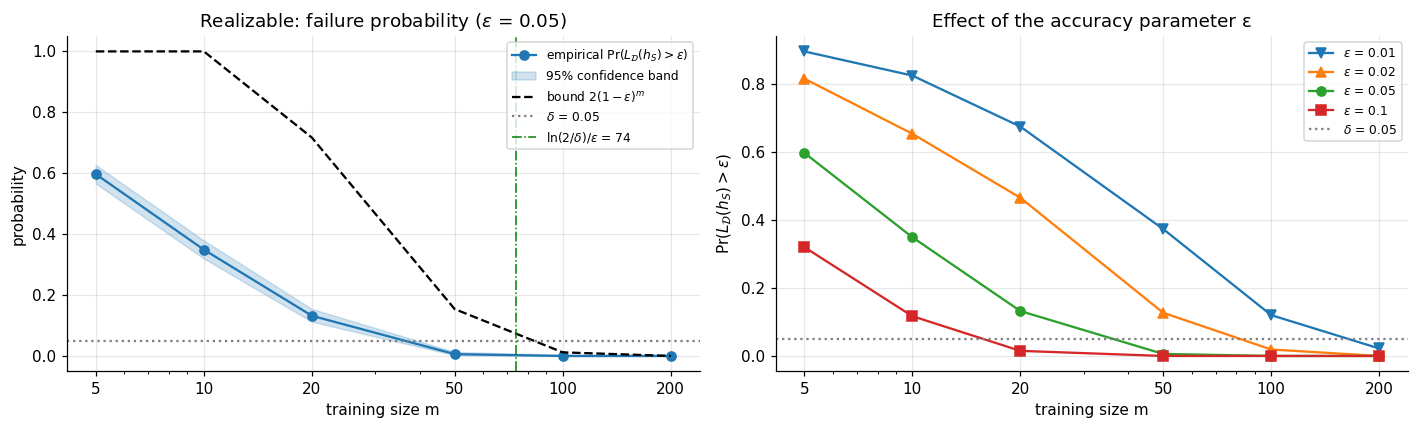

  eps | m=  5 | m= 10 | m= 20 | m= 50 | m=100 | m=200 | ln(2/delta)/eps
 0.01 | 0.895 | 0.824 | 0.674 | 0.373 | 0.120 | 0.022 | 369
 0.02 | 0.815 | 0.653 | 0.465 | 0.127 | 0.019 | 0.000 | 184
 0.05 | 0.597 | 0.349 | 0.132 | 0.006 | 0.000 | 0.000 | 74
  0.1 | 0.320 | 0.117 | 0.015 | 0.000 | 0.000 | 0.000 | 37


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
lo, hi = wilson_ci(P_real)
ax.plot(M_LIST, P_real, "o-", color=C_REAL, label=r"empirical $\Pr(L_\mathcal{D}(h_S) > \varepsilon)$")
ax.fill_between(M_LIST, lo, hi, color=C_REAL, alpha=0.2, label="95% confidence band")
ax.plot(M_LIST, bound_thr, "k--", label=r"bound $2(1-\varepsilon)^m$")
ax.axhline(DELTA, color="gray", ls=":", label=fr"$\delta$ = {DELTA}")
ax.axvline(m_needed_thr, color="green", ls="-.", lw=1, label=fr"$\ln(2/\delta)/\varepsilon$ = {m_needed_thr}")
ax.set_xscale("log"); ax.set_xticks(M_LIST); ax.set_xticklabels(M_LIST)
ax.set_xlabel("training size m"); ax.set_ylabel("probability"); ax.legend(fontsize=8)
ax.set_title(fr"Realizable: failure probability ($\varepsilon$ = {EPS})")

ax = axes[1]
for eps, mk in zip([0.01, 0.02, 0.05, 0.10], ["v", "^", "o", "s"]):
    ax.plot(M_LIST, prob_exceed(res_real, M_LIST, eps), marker=mk, label=fr"$\varepsilon$ = {eps}")
ax.axhline(DELTA, color="gray", ls=":", label=fr"$\delta$ = {DELTA}")
ax.set_xscale("log"); ax.set_xticks(M_LIST); ax.set_xticklabels(M_LIST)
ax.set_xlabel("training size m"); ax.set_ylabel(r"$\Pr(L_\mathcal{D}(h_S) > \varepsilon)$")
ax.set_title("Effect of the accuracy parameter ε"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'eps':>5} | " + " | ".join(f"m={m:>3}" for m in M_LIST) + " | ln(2/delta)/eps")
for eps in [0.01, 0.02, 0.05, 0.10]:
    print(f"{eps:>5} | " + " | ".join(f"{p:.3f}" for p in prob_exceed(res_real, M_LIST, eps)) + f" | {np.log(2 / DELTA) / eps:.0f}")


**Observations.**
- The estimated failure probability $\Pr(L_{\mathcal D}(h_S)>\varepsilon)$ decreases quickly: $0.597\to0.349\to0.132\to0.006\to0\to0$. It falls **below $\delta=0.05$ from $m=50$ on**. This is exactly the PAC guarantee: beyond a certain sample size, ERM is *approximately correct* ($L_{\mathcal D}\le\varepsilon$) with *high probability* ($\ge1-\delta$).
- The theoretical bound $2(1-\varepsilon)^m$ is always **above** the empirical curve, so it is valid. It is **conservative**: at $m=50$ it gives $0.154$ while we observe $0.006$. It predicts $m\ge74$ is sufficient, whereas $m=50$ already works in practice. The lecture's generic finite-class bound ($m\ge199$ for a grid of 1000 thresholds) is even more pessimistic, since it ignores the structure of the class and must hold for every distribution.
- The decrease is close to **exponential** in $m$, as predicted by $2e^{-\varepsilon m}$.
- **Effect of $\varepsilon$** (right plot and table): higher accuracy requires more data. To get below $\delta$, $\varepsilon=0.1$ needs $m=20$ ($0.015$), $\varepsilon=0.05$ needs $m=50$, $\varepsilon=0.02$ needs $m=100$, and $\varepsilon=0.01$ is still at $0.022$ only at $m=200$. The theory predicts the same ordering ($m\ge37,74,184,369$): the sample complexity in the realizable case scales like $1/\varepsilon$.


## 5. From PAC to Agnostic PAC

We now flip each label with probability $\eta$. The target $f_\theta$ still belongs to $\mathcal H$, but **no hypothesis has zero true error** anymore: the best one has $L_{\mathcal D}(h_\theta)=\eta$. The realizability assumption is violated, so the right framework is Agnostic PAC, whose guarantee is

$$\Pr\Big(L_{\mathcal D}(h_S)\le\min_{h\in\mathcal H}L_{\mathcal D}(h)+\varepsilon\Big)\ge1-\delta,\qquad\min_{h\in\mathcal H}L_{\mathcal D}(h)=\eta .$$

### 5.1 Can the empirical error still reach zero?

In [14]:
print(f"{'m':>5} | {'P(L_S = 0)':>10} | {'mean L_S':>9} | {'mean L_D':>9} | {'mean (L_D - L_S)':>17}   (eta = {ETA})")
for m in M_LIST_EXT:
    _, LS, LD = res_noisy[m]
    print(f"{m:>5} | {np.mean(LS == 0):>10.3f} | {LS.mean():>9.4f} | {LD.mean():>9.4f} | {np.mean(LD - LS):>17.4f}")

    m | P(L_S = 0) |  mean L_S |  mean L_D |  mean (L_D - L_S)   (eta = 0.1)
    5 |      0.725 |    0.0602 |    0.2313 |            0.1711
   10 |      0.404 |    0.0820 |    0.1725 |            0.0905
   20 |      0.169 |    0.0852 |    0.1392 |            0.0541
   50 |      0.014 |    0.0964 |    0.1167 |            0.0203
  100 |      0.000 |    0.0957 |    0.1083 |            0.0126
  200 |      0.000 |    0.0984 |    0.1039 |            0.0055
  500 |      0.000 |    0.0999 |    0.1015 |            0.0016
 1000 |      0.000 |    0.0994 |    0.1008 |            0.0015
 2000 |      0.000 |    0.0998 |    0.1004 |            0.0006
 5000 |      0.000 |    0.1000 |    0.1002 |            0.0002


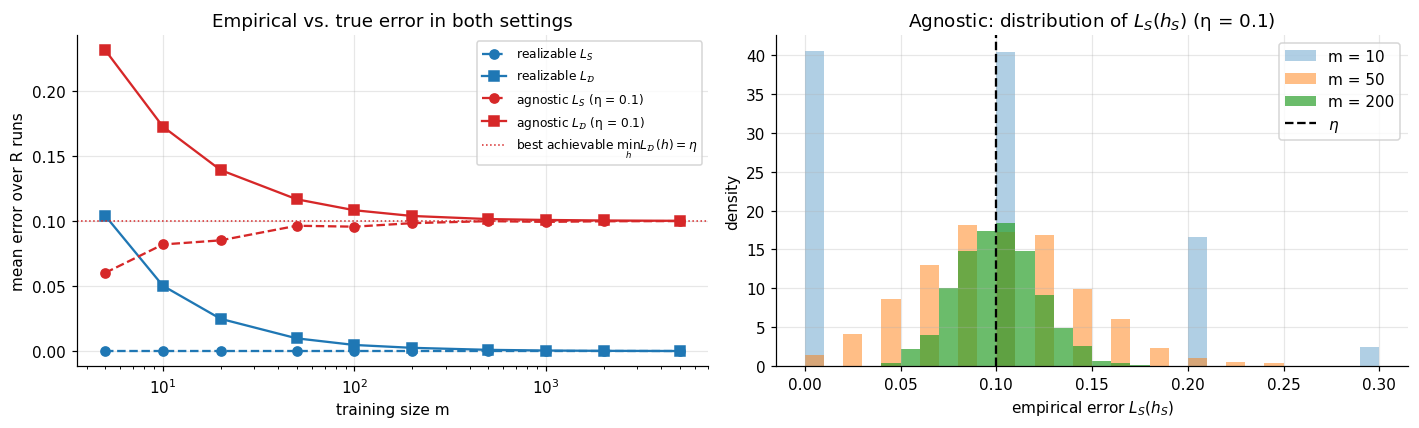

In [15]:
LSn, LDn, sLSn, sLDn = summary(res_noisy, M_LIST_EXT)
LSr_e, LDr_e, sLSr_e, sLDr_e = summary(res_real, M_LIST_EXT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(M_LIST_EXT, LSr_e, "o--", color=C_REAL, label=r"realizable $L_S$")
ax.plot(M_LIST_EXT, LDr_e, "s-",  color=C_REAL, label=r"realizable $L_\mathcal{D}$")
ax.plot(M_LIST_EXT, LSn, "o--", color=C_NOISY, label=fr"agnostic $L_S$ (η = {ETA})")
ax.plot(M_LIST_EXT, LDn, "s-",  color=C_NOISY, label=fr"agnostic $L_\mathcal{{D}}$ (η = {ETA})")
ax.axhline(ETA, color=C_NOISY, ls=":", lw=1, label=r"best achievable $\min_h L_\mathcal{D}(h)=\eta$")
ax.set_xscale("log"); ax.set_xlabel("training size m"); ax.set_ylabel("mean error over R runs")
ax.set_title("Empirical vs. true error in both settings"); ax.legend(fontsize=8)

ax = axes[1]
bins = np.linspace(0, 0.3, 31)
for m, a in zip([10, 50, 200], [0.35, 0.5, 0.7]):
    ax.hist(res_noisy[m][1], bins=bins, alpha=a, label=f"m = {m}", density=True)
ax.axvline(ETA, color="k", ls="--", label=r"$\eta$")
ax.set_xlabel(r"empirical error $L_S(h_S)$"); ax.set_ylabel("density")
ax.set_title(fr"Agnostic: distribution of $L_S(h_S)$ (η = {ETA})"); ax.legend()
plt.tight_layout(); plt.show()


**Answer: in general, no.**
- With noise, the empirical error can be zero only **by luck** on very small samples: $\Pr(L_S=0)=0.725$ for $m=5$, $0.404$ for $m=10$, $0.014$ for $m=50$, and **never** for $m\ge100$. In those small cases, a zero training error does not mean the model is good: the mean true error at $m=5$ is $0.231$. It means the sample happened to contain no (or only consistent) flipped labels.
- As $m$ grows, $L_S(h_S)$ concentrates around $\eta=0.1$ (histogram): $0.0984$ at $m=200$, $0.1000$ at $m=5000$. The flipped labels are an **irreducible error** that no threshold can explain.
- The empirical error is **optimistically biased**: on average $L_S(h_S)<\eta<L_{\mathcal D}(h_S)$. ERM partly fits the noise of the particular sample, so the training error underestimates the true error. This gap shrinks with $m$: $0.171$ ($m=5$), $0.020$ ($m=50$), $0.0055$ ($m=200$), $0.0002$ ($m=5000$).
- In the realizable case, by contrast, the empirical error is exactly $0$ for every $m$ and the true error goes to $0$.


### 5.2 Does increasing $m$ still improve generalization?
We compare two events for each $m$:
- the **PAC event** $L_{\mathcal D}(h_S)>\varepsilon$ (a failure in the realizable sense);
- the **Agnostic PAC event** $L_{\mathcal D}(h_S)>\min_{h}L_{\mathcal D}(h)+\varepsilon=\eta+\varepsilon$.

In [16]:
P_noisy_pac  = prob_exceed(res_noisy, M_LIST_EXT, EPS)              # P(L_D > eps)
P_noisy_apac = prob_exceed(res_noisy, M_LIST_EXT, EPS, offset=ETA)  # P(L_D > eta + eps)
P_real_ext   = prob_exceed(res_real,  M_LIST_EXT, EPS)

m_emp_apac = next((m for m in M_LIST_EXT if prob_exceed(res_noisy, [m], EPS, offset=ETA)[0] <= DELTA), None)
m_hoeff = int(np.ceil(2 * np.log(2 * 1000 / DELTA) / EPS**2))       # lecture bound, |H| = 1000

print(f"{'m':>5} | {'realizable P(L>eps)':>20} | {'agnostic P(L>eps)':>18} | {'agnostic P(L>eta+eps)':>22}")
for i, m in enumerate(M_LIST_EXT):
    print(f"{m:>5} | {P_real_ext[i]:>20.3f} | {P_noisy_pac[i]:>18.3f} | {P_noisy_apac[i]:>22.3f}")
print(f"\nSmallest tested m with P(L_D > eta + eps) <= delta : m = {m_emp_apac}")
print(f"Agnostic lecture bound 2 ln(2|H|/delta)/eps^2 (|H| = 1000): m >= {m_hoeff}")

    m |  realizable P(L>eps) |  agnostic P(L>eps) |  agnostic P(L>eta+eps)
    5 |                0.597 |              1.000 |                  0.646
   10 |                0.349 |              1.000 |                  0.453
   20 |                0.132 |              1.000 |                  0.243
   50 |                0.006 |              1.000 |                  0.074
  100 |                0.000 |              1.000 |                  0.021
  200 |                0.000 |              1.000 |                  0.000
  500 |                0.000 |              1.000 |                  0.000
 1000 |                0.000 |              1.000 |                  0.000
 2000 |                0.000 |              1.000 |                  0.000
 5000 |                0.000 |              1.000 |                  0.000

Smallest tested m with P(L_D > eta + eps) <= delta : m = 100
Agnostic lecture bound 2 ln(2|H|/delta)/eps^2 (|H| = 1000): m >= 8478


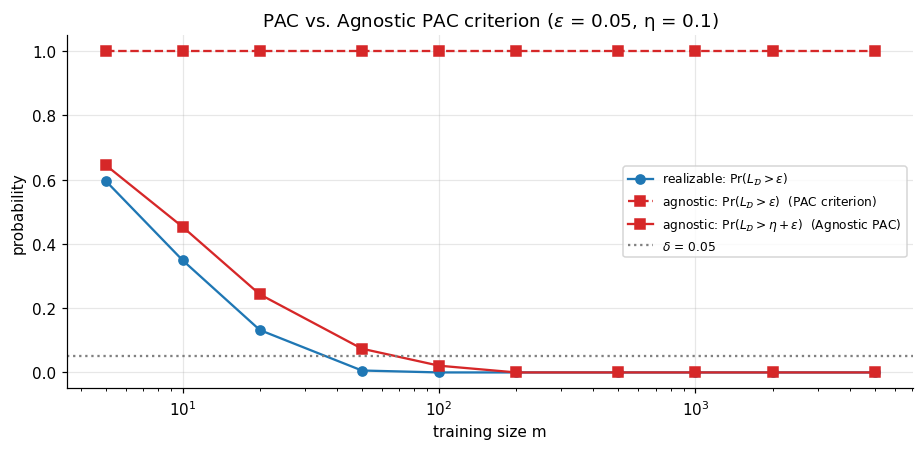

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(M_LIST_EXT, P_real_ext,   "o-", color=C_REAL,  label=r"realizable: $\Pr(L_\mathcal{D} > \varepsilon)$")
ax.plot(M_LIST_EXT, P_noisy_pac,  "s--", color=C_NOISY, label=r"agnostic: $\Pr(L_\mathcal{D} > \varepsilon)$  (PAC criterion)")
ax.plot(M_LIST_EXT, P_noisy_apac, "s-", color=C_NOISY, label=r"agnostic: $\Pr(L_\mathcal{D} > \eta + \varepsilon)$  (Agnostic PAC)")
ax.axhline(DELTA, color="gray", ls=":", label=fr"$\delta$ = {DELTA}")
ax.set_xscale("log"); ax.set_xlabel("training size m"); ax.set_ylabel("probability")
ax.set_title(fr"PAC vs. Agnostic PAC criterion ($\varepsilon$ = {EPS}, η = {ETA})")
ax.legend(fontsize=8, loc="center right"); plt.tight_layout(); plt.show()


**Answer: yes, but towards $\eta$, not towards $0$.**
- The **PAC criterion fails completely**: $\Pr(L_{\mathcal D}(h_S)>\varepsilon)=1$ for every $m$. This is unavoidable because every hypothesis has $L_{\mathcal D}(h)\ge\eta=0.1>\varepsilon=0.05$. No amount of data can satisfy the realizable PAC guarantee when realizability is violated.
- The **Agnostic PAC criterion is satisfied**: $\Pr(L_{\mathcal D}(h_S)>\eta+\varepsilon)$ goes $0.646\to0.453\to0.243\to0.074\to0.021\to0$. It falls below $\delta$ from $m=100$. More data still improves generalisation, but the target is now the **best achievable error** $\min_hL_{\mathcal D}(h)=\eta$.
- **Agnostic learning costs more data.** For the same $(\varepsilon,\delta)$, the realizable case needs $m=50$ while the noisy case needs $m=100$, and the agnostic curve lies above the realizable one for every $m$. This matches the lectures: removing the realizability assumption has a statistical price.
- The lecture's agnostic bound $m\ge2\ln(2|\mathcal H|/\delta)/\varepsilon^2=8478$ (for a grid of 1000 thresholds) is about **85 times larger** than what we observe. It combines Hoeffding with a union bound and must hold for **every** distribution, so it is very pessimistic for this simple problem.


### 5.3 Effect of the noise level $\eta$
We repeat the agnostic experiment for several noise rates. We look at the **excess risk** $L_{\mathcal D}(h_S)-\min_hL_{\mathcal D}(h)=L_{\mathcal D}(h_S)-\eta$, i.e. how far ERM is from the best hypothesis of the class.

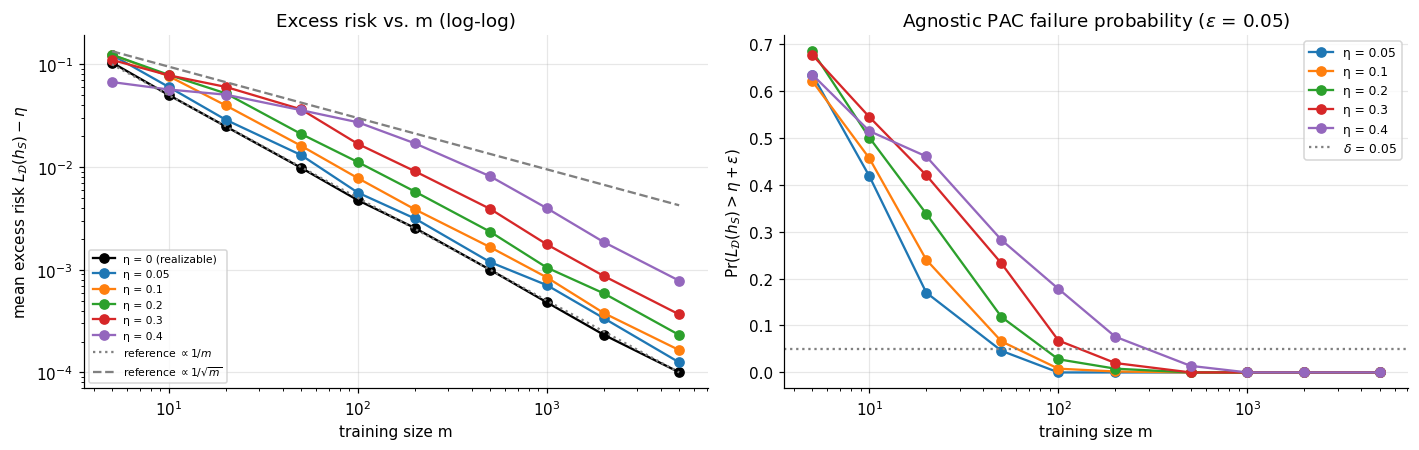

  eta | m=20 | m=100 | m=1000 | m=5000   (mean excess risk)
  0.0 | 0.0249 | 0.0048 | 0.0005 | 0.0001
 0.05 | 0.0289 | 0.0056 | 0.0007 | 0.0001
  0.1 | 0.0398 | 0.0078 | 0.0008 | 0.0002
  0.2 | 0.0522 | 0.0112 | 0.0010 | 0.0002
  0.3 | 0.0603 | 0.0168 | 0.0018 | 0.0004
  0.4 | 0.0507 | 0.0273 | 0.0040 | 0.0008

eta = 0.05: smallest tested m with P(L_D > eta + eps) <= delta:    50 | log-log slope of excess risk (m >= 50): -0.98
eta = 0.10: smallest tested m with P(L_D > eta + eps) <= delta:   100 | log-log slope of excess risk (m >= 50): -0.99
eta = 0.20: smallest tested m with P(L_D > eta + eps) <= delta:   100 | log-log slope of excess risk (m >= 50): -0.99
eta = 0.30: smallest tested m with P(L_D > eta + eps) <= delta:   200 | log-log slope of excess risk (m >= 50): -1.00
eta = 0.40: smallest tested m with P(L_D > eta + eps) <= delta:   500 | log-log slope of excess risk (m >= 50): -0.86
eta = 0.00 (realizable): log-log slope of mean true error (m >= 50): -1.00


In [18]:
res_eta = {eta: run_experiment(M_LIST_EXT, eta=eta, R=500) for eta in ETAS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(M_LIST_EXT, [res_real[m][2].mean() for m in M_LIST_EXT], "o-", color="k", label="η = 0 (realizable)")
for eta in ETAS:
    ax.plot(M_LIST_EXT, [np.mean(res_eta[eta][m][2] - eta) for m in M_LIST_EXT], "o-", label=f"η = {eta}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("training size m"); ax.set_ylabel(r"mean excess risk $L_\mathcal{D}(h_S) - \eta$")
M_arr = np.array(M_LIST_EXT)
ax.plot(M_arr, 0.5 / M_arr, color="gray", ls=":", lw=1.5, label=r"reference $\propto 1/m$")
ax.plot(M_arr, 0.3 / np.sqrt(M_arr), color="gray", ls="--", lw=1.5, label=r"reference $\propto 1/\sqrt{m}$")
ax.set_title("Excess risk vs. m (log-log)"); ax.legend(fontsize=7)

ax = axes[1]
for eta in ETAS:
    ax.plot(M_LIST_EXT, [np.mean(res_eta[eta][m][2] - eta > EPS) for m in M_LIST_EXT], "o-", label=f"η = {eta}")
ax.axhline(DELTA, color="gray", ls=":", label=fr"$\delta$ = {DELTA}")
ax.set_xscale("log"); ax.set_xlabel("training size m"); ax.set_ylabel(r"$\Pr(L_\mathcal{D}(h_S) > \eta + \varepsilon)$")
ax.set_title(fr"Agnostic PAC failure probability ($\varepsilon$ = {EPS})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'eta':>5} | " + " | ".join(f"m={m}" for m in [20, 100, 1000, 5000]) + "   (mean excess risk)")
for eta in [0.0] + ETAS:
    r = res_real if eta == 0 else res_eta[eta]
    print(f"{eta:>5} | " + " | ".join(f"{np.mean(r[m][2] - eta):.4f}" for m in [20, 100, 1000, 5000]))

print()
for eta in ETAS:
    m_ok = next((m for m in M_LIST_EXT if np.mean(res_eta[eta][m][2] - eta > EPS) <= DELTA), None)
    slope = np.polyfit(np.log(M_LIST_EXT[3:]), np.log([np.mean(res_eta[eta][m][2] - eta) for m in M_LIST_EXT[3:]]), 1)[0]
    print(f"eta = {eta:.2f}: smallest tested m with P(L_D > eta + eps) <= delta: {m_ok:>5} | log-log slope of excess risk (m >= 50): {slope:.2f}")
slope0 = np.polyfit(np.log(M_LIST_EXT[3:]), np.log([res_real[m][2].mean() for m in M_LIST_EXT[3:]]), 1)[0]
print(f"eta = 0.00 (realizable): log-log slope of mean true error (m >= 50): {slope0:.2f}")


**Observations.**
- For every $\eta<1/2$, the excess risk $L_{\mathcal D}(h_S)-\eta$ **goes to 0**: ERM always converges to the best hypothesis of the class. Learning remains possible, which is the Agnostic PAC promise.
- **More noise means more data.** At $m=100$ the mean excess risk is $0.0048$ ($\eta=0$), $0.0078$ ($\eta=0.1$), $0.0168$ ($\eta=0.3$) and $0.0273$ ($\eta=0.4$). The sample size needed to reach $\Pr(L_{\mathcal D}>\eta+\varepsilon)\le\delta$ grows from $m=50$ ($\eta=0.05$) to $m=100$ ($\eta=0.1,0.2$), $m=200$ ($\eta=0.3$) and $m=500$ ($\eta=0.4$). As $\eta\to1/2$ the labels carry less and less information about $x$; at $\eta=1/2$ they would be independent of $x$ and every hypothesis would have error $1/2$.
- **Rate of convergence (an honest observation).** The log-log slopes are close to $-1$ (from $-0.86$ to $-1.00$): the excess risk decreases like $1/m$, just like in the realizable case, and not like $1/\sqrt m$. This does **not** contradict the lectures. The agnostic sample complexity $O(1/\varepsilon^2)$ is a **worst-case** guarantee over all distributions. Our noise is "benign": each label is flipped with the same probability $\eta<1/2$, so $f_\theta$ remains the Bayes-optimal predictor and the signal-to-noise ratio $1-2\eta$ is bounded away from 0. Under such conditions faster rates are known to hold. The price of noise appears in the **constant** (curves shifted upwards as $\eta$ grows), not in the exponent here. The $\eta=0.4$ curve has the flattest slope ($-0.86$), consistent with the fact that the problem gets harder as $1-2\eta\to0$.
- Small detail: at $m=20$ the excess risk is lower for $\eta=0.4$ than for $\eta=0.3$. This is because the excess risk equals $(1-2\eta)|\hat t-\theta|$: with $\eta=0.4$ even a badly placed threshold is penalised by a factor of only $0.2$.


### 5.4 Link with uniform convergence
The lecture's proof of Agnostic PAC learnability relies on **uniform convergence**: with enough data, $|L_S(h)-L_{\mathcal D}(h)|$ is small **simultaneously for all** $h\in\mathcal H$. We measure the worst-case deviation
$$\Delta_S=\sup_{t\in[0,1]}\big|L_S(h_t)-L_{\mathcal D}(h_t)\big|$$
(approximated on a grid of 1001 thresholds) and compare it with the Hoeffding + union bound for a discretised class of $|\mathcal H|=1001$ thresholds: with probability $\ge1-\delta$, $\Delta_S\le\sqrt{\ln(2|\mathcal H|/\delta)/(2m)}$.

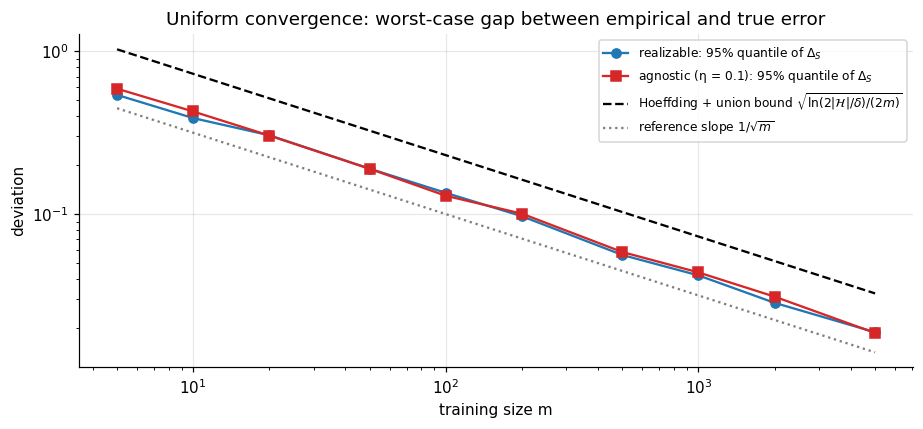

m =     5 | 95% quantile of Delta_S: realizable 0.540, agnostic 0.590 | bound 1.029
m =    10 | 95% quantile of Delta_S: realizable 0.389, agnostic 0.427 | bound 0.728
m =    20 | 95% quantile of Delta_S: realizable 0.305, agnostic 0.304 | bound 0.515
m =    50 | 95% quantile of Delta_S: realizable 0.190, agnostic 0.190 | bound 0.326
m =   100 | 95% quantile of Delta_S: realizable 0.135, agnostic 0.130 | bound 0.230
m =   200 | 95% quantile of Delta_S: realizable 0.097, agnostic 0.101 | bound 0.163
m =   500 | 95% quantile of Delta_S: realizable 0.056, agnostic 0.058 | bound 0.103
m =  1000 | 95% quantile of Delta_S: realizable 0.042, agnostic 0.044 | bound 0.073
m =  2000 | 95% quantile of Delta_S: realizable 0.029, agnostic 0.031 | bound 0.051
m =  5000 | 95% quantile of Delta_S: realizable 0.019, agnostic 0.019 | bound 0.033


In [19]:
T_GRID = np.linspace(0, 1, 1001)

def uniform_deviation(x, y, eta, t_grid=T_GRID):
    # sup_t |L_S(h_t) - L_D(h_t)| over a grid of thresholds (vectorised)
    m = len(x); order = np.argsort(x); xs, ys = x[order], y[order]
    k = np.searchsorted(xs, t_grid, side="right")            # points with x <= t are predicted 0
    pos_left = np.concatenate([[0], np.cumsum(ys)])[k]
    neg_right = (m - k) - (ys.sum() - pos_left)
    LS = (pos_left + neg_right) / m
    LD = true_error_exact(t_grid, eta=eta)
    return np.max(np.abs(LS - LD))

dev = {eta: [] for eta in [0.0, ETA]}
for eta in dev:
    for m in M_LIST_EXT:
        dev[eta].append(np.quantile([uniform_deviation(*generate_data(m, eta=eta), eta) for _ in range(300)], 1 - DELTA))
uc_bound = np.sqrt(np.log(2 * len(T_GRID) / DELTA) / (2 * np.array(M_LIST_EXT)))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(M_LIST_EXT, dev[0.0], "o-", color=C_REAL, label=r"realizable: 95% quantile of $\Delta_S$")
ax.plot(M_LIST_EXT, dev[ETA], "s-", color=C_NOISY, label=fr"agnostic (η = {ETA}): 95% quantile of $\Delta_S$")
ax.plot(M_LIST_EXT, uc_bound, "k--", label=r"Hoeffding + union bound $\sqrt{\ln(2|\mathcal{H}|/\delta)/(2m)}$")
ax.plot(M_LIST_EXT, 1 / np.sqrt(M_LIST_EXT), color="gray", ls=":", label=r"reference slope $1/\sqrt{m}$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("training size m"); ax.set_ylabel("deviation")
ax.set_title("Uniform convergence: worst-case gap between empirical and true error")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

for i, m in enumerate(M_LIST_EXT):
    print(f"m = {m:>5} | 95% quantile of Delta_S: realizable {dev[0.0][i]:.3f}, agnostic {dev[ETA][i]:.3f} | bound {uc_bound[i]:.3f}")


**Observations.**
- In both settings, the worst-case deviation $\Delta_S$ decreases like $1/\sqrt m$ (parallel to the dotted reference line): from $0.19$ at $m=50$ to $0.019$ at $m=5000$, i.e. 10 times smaller for 100 times more data.
- The 95 % quantile of $\Delta_S$ always stays **below** the Hoeffding + union bound (e.g. $0.097$ vs. $0.163$ at $m=200$). The class therefore has the **uniform convergence property**, as predicted for finite (discretised) classes: the sample becomes $\varepsilon$-representative with probability $\ge1-\delta$.
- Uniform convergence behaves the same with or without noise. This explains why ERM works in both settings: once $S$ is $\frac\varepsilon2$-representative, ERM is within $\varepsilon$ of the best hypothesis.
- The faster behaviour of the realizable case does not come from uniform convergence but from **realizability itself**: ERM only has to choose among hypotheses with $L_S=0$, which leads to the $1/\varepsilon$ bound instead of $1/\varepsilon^2$.



## 6. Conclusion: PAC vs. Agnostic PAC

| | **Realizable (PAC)** | **Agnostic (label noise $\eta=0.1$)** |
|---|---|---|
| Best achievable true error | $0$ | $\eta=0.1$ (Bayes error) |
| Empirical error of ERM | always exactly $0$ | $0$ only by luck for tiny $m$; $\to\eta$ as $m$ grows |
| True error of ERM | $\to0$, roughly $0.5/m$ | $\to\eta$; the excess risk $\to0$ |
| $\Pr(L_{\mathcal D}>\varepsilon)$ | $\le\delta$ from $m=50$ | $=1$ for every $m$ (PAC criterion impossible) |
| $\Pr(L_{\mathcal D}>\min_hL_{\mathcal D}(h)+\varepsilon)$ | $\le\delta$ from $m=50$ | $\le\delta$ from $m=100$ |
| Lecture bound for $\varepsilon=\delta=0.05$, $|\mathcal H|=1000$ | $m\ge199$ ($1/\varepsilon$) | $m\ge8478$ ($1/\varepsilon^2$) |

**Answers to the three questions.**
1. **Can the empirical error still reach zero?** Only by chance on very small samples, where it is a symptom of overfitting rather than of good learning. For $m\ge100$ it never happened in 1000 runs, and $L_S(h_S)$ converges to the noise rate $\eta$.
2. **Does more data still improve generalisation?** Yes. The true error decreases and its variance shrinks, but it converges to $\eta$ instead of $0$. Noise makes learning more expensive: twice as many examples for $\eta=0.1$, and ten times as many for $\eta=0.4$, to reach the same $(\varepsilon,\delta)$ guarantee.
3. **Relation to the lectures.**
   - The realizable experiment verifies **PAC learnability**: there is a sample size beyond which $\Pr(L_{\mathcal D}(h_S)\le\varepsilon)\ge1-\delta$, and the failure probability decays exponentially, as in the proof based on independence and the union bound.
   - With noise the realizability assumption fails, so the PAC guarantee becomes **impossible** ($\Pr(L_{\mathcal D}>\varepsilon)=1$). The right objective is the **Agnostic PAC** one, comparing ERM with the best hypothesis of the class, and ERM achieves it.
   - **Uniform convergence** is observed directly: the worst-case gap between empirical and true error shrinks like $1/\sqrt m$ and stays below the Hoeffding + union bound, which is exactly the mechanism of the lecture's proof.
   - The theoretical bounds are always **valid but conservative** (up to a factor of about 4 in the realizable case and about 85 in the agnostic case), because they hold for every distribution.

**Limitations and possible extensions.** The study uses a very simple 1-D class, a uniform input distribution and symmetric label noise, under which the target stays Bayes-optimal. This explains the fast $1/m$ rates observed even with noise. Natural extensions would be: a non-uniform distribution, noise that depends on $x$ (harder, closer to the worst case), or a target **outside** the hypothesis class (e.g. an interval $[a,b]$ learned with thresholds), which would add an approximation error on top of the estimation error.


## References

1. A. Ismail-Fawaz. *Statistical and Machine Learning*, lecture slides, Sessions 1–3 (Introduction; Learnability; Learning via Uniform Convergence). Université de Haute-Alsace.
2. S. Shalev-Shwartz and S. Ben-David (2014). *Understanding Machine Learning: From Theory to Algorithms*. Cambridge University Press, Chapters 2–4.
3. W. Hoeffding (1963). Probability inequalities for sums of bounded random variables. *Journal of the American Statistical Association*, 58(301), 13–30. (Used in §5.4.)
4. E. B. Wilson (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209–212. (Confidence intervals in §4.)
5. P. Massart and É. Nédélec (2006). Risk bounds for statistical learning. *The Annals of Statistics*, 34(5), 2326–2366. (Fast rates under bounded noise, discussed in §5.3.)
